# Experiment 8: Line Detection Using Hough Transformation

## Aim
To implement and evaluate the Hough Transform for parametric line detection, comparing Cartesian slope-intercept $(m, c)$ parameter space against Polar/Normal $(r, \theta)$ parameter space on synthetic multi-line imagery, and to implement an iterative weight peeling algorithm for unsupervised peak detection without prior knowledge of line count.

## Key Objectives
1. Construct a synthetic ground-truth image containing multiple lines with known slope and intercept parameters $(m, c)$.
2. Implement sparse, intensity-weighted random pixel sampling to simulate edge detector outputs.
3. Design and implement 2D discrete accumulators for both $(m, c)$ Cartesian space and $(r, \theta)$ Polar space.
4. Implement a peak-finding algorithm combining $3 \times 3$ spatial box filtering with iterative weight peeling (suppression of inliers).
5. Compare detection accuracy, parameter stability, and singularity handling between the two representations.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

# Configure reproducible random generator and canvas dimensions
rng = np.random.default_rng(0)
H = W = 500


### Step 1: Synthetic Ground-Truth Image Generation
We define 3 ground-truth lines with distinct slopes and intercepts:
- Line 1: $m = 0.37, c = 63$ (shallow positive slope)
- Line 2: $m = -1.13, c = 447$ (moderate negative slope)
- Line 3: $m = 2.21, c = -190$ (steep positive slope)

The parameters are deliberately chosen off-grid to rigorously test accumulator discretization tolerance and interpolation fidelity.


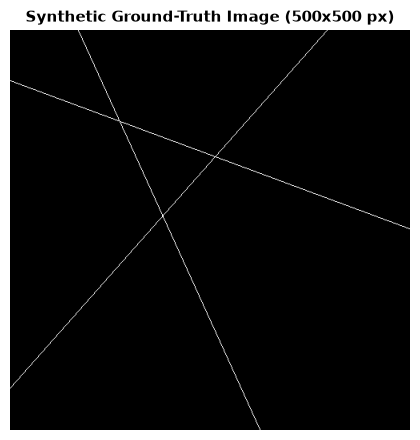

Canvas: 500x500 px | Active line pixels: 1445


In [2]:
true_lines = [(0.37, 63), (-1.13, 447), (2.21, -190)]

# Rasterize lines on an empty 500x500 8-bit grayscale canvas
img = np.zeros((H, W), dtype=np.uint8)
for m, c in true_lines:
    x0, y0 = 0, round(c)
    x1, y1 = W - 1, round(m * (W - 1) + c)
    cv2.line(img, (x0, y0), (x1, y1), 255, 1)

plt.figure(figsize=(4.5, 4.5), dpi=100)
plt.imshow(img, cmap="gray")
plt.title("Synthetic Ground-Truth Image (500x500 px)", fontsize=11, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

print(f"Canvas: {H}x{W} px | Active line pixels: {(img > 0).sum()}")


### Step 2: Random Pixel Sampling & Intensity-Weighted Voting
In real-world computer vision pipelines, line detection is performed on edge maps produced by edge operators (e.g., Canny or Sobel). To emulate this sparse, noisy condition:
- We randomly sample 20% of all image pixels ($n = 50,000$ points).
- Each sampled point $(x, y)$ votes with a weight proportional to its normalized intensity $w(x, y) = I(x, y) / 255.0 \in [0, 1]$.
- Background pixels ($w = 0$) contribute zero votes, while line pixels ($w = 1$) cast full votes.


Sampled 50000 pixels (20% of canvas); Active edge pixels (w > 0): 280


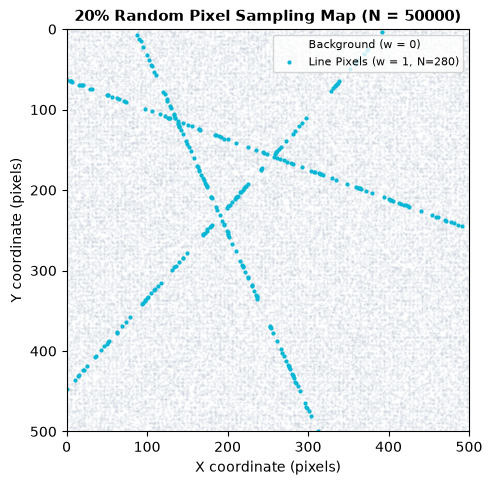

In [3]:
n = int(0.20 * H * W)
k = rng.choice(H * W, n, replace=False)
x, y = k % W, k // W
w = img[y, x] / 255.0
on = w > 0

print(f"Sampled {n} pixels ({100*n/(H*W):.0f}% of canvas); Active edge pixels (w > 0): {on.sum()}")

# Visualizing random sample with fixed aspect ratio (no stretching!)
fig, ax = plt.subplots(figsize=(5, 5), dpi=100)
ax.scatter(x[~on], y[~on], s=0.2, color="#94a3b8", alpha=0.15, label="Background (w = 0)")
ax.scatter(x[on], y[on], s=4.0, color="#06b6d4", label=f"Line Pixels (w = 1, N={on.sum()})")
ax.set_xlim(0, W)
ax.set_ylim(H, 0)
ax.set_aspect("equal")  # Enforce square aspect ratio!
ax.set_title(f"20% Random Pixel Sampling Map (N = {n})", fontsize=11, fontweight="bold")
ax.set_xlabel("X coordinate (pixels)")
ax.set_ylabel("Y coordinate (pixels)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


### Step 3: Accumulator Parameter Space Discretization
We implement two dual parameter representations:

1. **Cartesian Slope-Intercept Space $(m, c)$:**
   $$y = mx + c \iff c = -x m + y$$
   Each point $(x_i, y_i)$ maps to a straight line in $(m, c)$ space.
   - Discretization: $\Delta c = 5$ px, $\Delta m = \Delta c / W = 0.01$, covering $m \in [-5, 5]$ and $c \in [-2500, 3000]$.
   - *Limitation:* Vertical lines ($m \to \pm\infty$) cannot be represented without infinite accumulator bins.

2. **Polar / Normal Space $(r, \theta)$ (Duda & Hart):**
   $$r = x \cos\theta + y \sin\theta$$
   Each point $(x_i, y_i)$ maps to a sinusoid in $(r, \theta)$ space.
   - Discretization: $\Delta \theta = 0.5^\circ$ ($0^\circ$ to $180^\circ$), $\Delta r = 1$ px ($-\text{diag}$ to $+\text{diag}$).
   - *Advantage:* Bounded parameter space for all line orientations with uniform angular resolution.


In [4]:
dc = 5
m_vals = np.arange(-5, 5.001, dc / W)                  # dm = dc / W (0.01), matched resolution
c_min, c_max = -2500, 3000                             # Covers reachable range for |m| <= 5
n_c = (c_max - c_min) // dc + 1

diag = int(np.ceil(np.hypot(H, W)))
thetas = np.deg2rad(np.arange(0, 180, 0.5))
r_vals = np.arange(-diag, diag + 1)

print(f"(m, c) Accumulator Grid: {len(m_vals)} m bins x {n_c} c bins = {len(m_vals)*n_c} cells")
print(f"(r, θ) Accumulator Grid: {len(thetas)} θ bins x {len(r_vals)} r bins = {len(thetas)*len(r_vals)} cells")

def hough_mc(weights):
    acc = np.zeros((len(m_vals), n_c))
    for i, m in enumerate(m_vals):
        idx = np.round((y - m * x - c_min) / dc).astype(int)
        ok = (idx >= 0) & (idx < n_c)
        acc[i] = np.bincount(idx[ok], weights=weights[ok], minlength=n_c)
    return acc

def hough_rt(weights):
    acc = np.zeros((len(thetas), len(r_vals)))
    for i, t in enumerate(thetas):
        idx = np.round(x * np.cos(t) + y * np.sin(t)).astype(int) + diag
        ok = (idx >= 0) & (idx < len(r_vals))
        acc[i] = np.bincount(idx[ok], weights=weights[ok], minlength=len(r_vals))
    return acc


(m, c) Accumulator Grid: 1001 m bins x 1101 c bins = 1102101 cells
(r, θ) Accumulator Grid: 360 θ bins x 1417 r bins = 510120 cells


### Step 4: Spatial Box Filtering & Iterative Weight Peeling Peak Finding
Standard thresholding often yields clusters of duplicate peaks around strong lines due to voting spread. We employ an iterative peeling strategy:
1. **Spatial Smoothing:** Convolve the accumulator with a $3 \times 3$ box filter (`cv2.boxFilter`) to coalesce neighboring votes.
2. **Global Argmax:** Locate the strongest peak $(i^*, j^*)$. If votes $< \text{MIN\_VOTES} = 12$, stop.
3. **Inlier Identification:** Find all sampled pixels whose perpendicular geometric distance to the detected line is within tolerance $\text{TOL} = 8$ px.
4. **Weight Invalidation (Peeling):** Set the voting weight of identified inliers to zero ($w_{\text{left}}[\text{near}] = 0$).
5. **Re-accumulation:** Re-vote using only remaining unexplained points. This cleanly reveals secondary lines without interference from previously detected lines.


In [5]:
MIN_VOTES = 12        # Minimum votes required (approx half the sampled points on a 250px line)
TOL = 8               # Orthogonal distance tolerance in pixels

def dist_mc(i, j):
    m, c = m_vals[i], c_min + j * dc
    return np.abs(y - m * x - c) / np.hypot(1, m)

def dist_rt(i, j):
    return np.abs(x * np.cos(thetas[i]) + y * np.sin(thetas[i]) - r_vals[j])

def peel(hough_fn, dist_fn):
    w_left = w.copy()
    first_acc = hough_fn(w_left)
    acc = first_acc
    found = []
    while True:
        sm = cv2.boxFilter(acc.astype(np.float32), -1, (3, 3), normalize=False)
        i, j = np.unravel_index(sm.argmax(), sm.shape)
        if sm[i, j] < MIN_VOTES:
            break
        found.append((i, j, sm[i, j]))
        near = dist_fn(i, j) <= TOL
        if w_left[near].sum() == 0:
            break
        w_left[near] = 0
        acc = hough_fn(w_left)
    return first_acc, found

print("Running iterative peeling on (m, c) space...")
acc_mc, peaks_mc = peel(hough_mc, dist_mc)

print("Running iterative peeling on (r, θ) space...")
acc_rt, peaks_rt = peel(hough_rt, dist_rt)

# Convert peak indices to physical line parameters
est_mc = [(float(m_vals[i]), float(c_min + j * dc)) for i, j, _ in peaks_mc]
est_rt = []
for i, j, _ in peaks_rt:
    t, r = thetas[i], r_vals[j]
    if np.sin(t) > 1e-6:
        est_rt.append((float(-np.cos(t) / np.sin(t)), float(r / np.sin(t))))
    else:
        est_rt.append((np.nan, np.nan))

print(f"Detected {len(est_mc)} lines in (m, c) space and {len(est_rt)} lines in (r, θ) space.")


Running iterative peeling on (m, c) space...


Running iterative peeling on (r, θ) space...


Detected 3 lines in (m, c) space and 3 lines in (r, θ) space.


### Step 5: Parameter Comparison & Reconstructed Edge Lines
We evaluate the detected parameters against the ground-truth lines and reconstruct the detected lines visually on image overlays.


Total sampled pixels: 50000 | Total active vote weight: 280

Line   | Ground Truth (m, c)    | Detected (m, c)        | Detected (r, θ)       
---------------------------------------------------------------------------
Line 1  | m =  0.37, c =   63.0   | m =  0.36, c =   70.0   | m =  0.38, c =   62.1
Line 2  | m = -1.13, c =  447.0   | m = -1.13, c =  450.0   | m = -1.13, c =  448.2
Line 3  | m =  2.21, c = -190.0   | m =  2.17, c = -180.0   | m =  2.14, c = -179.8


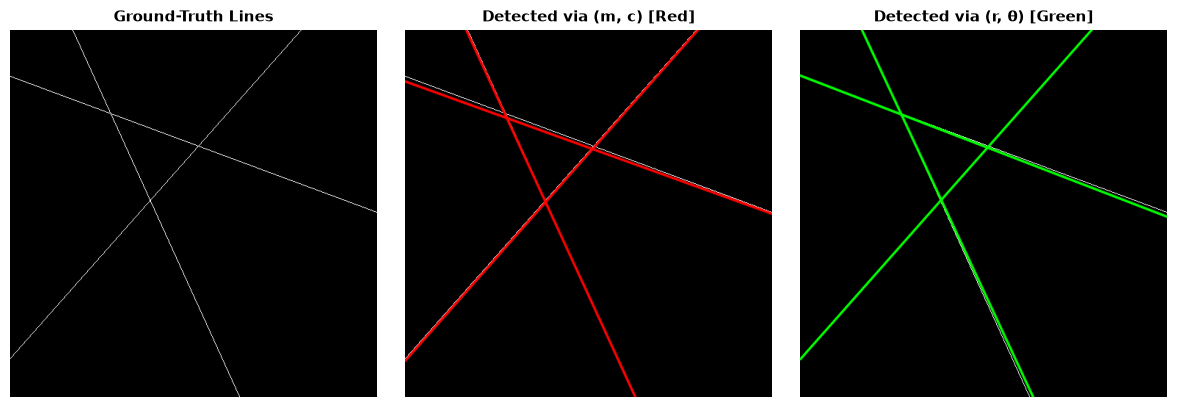

In [6]:
print(f"Total sampled pixels: {n} | Total active vote weight: {w.sum():.0f}\n")
print(f"{'Line':<6} | {'Ground Truth (m, c)':<22} | {'Detected (m, c)':<22} | {'Detected (r, θ)':<22}")
print("-" * 75)
for idx, (tm, tc) in enumerate(true_lines, 1):
    # Match with closest detected line
    mc_m = min(est_mc, key=lambda p: abs(p[0] - tm) + abs(p[1] - tc) / 100)
    rt_m = min(est_rt, key=lambda p: abs(p[0] - tm) + abs(p[1] - tc) / 100)
    print(f"Line {idx:<2} | m = {tm:5.2f}, c = {tc:6.1f}   | m = {mc_m[0]:5.2f}, c = {mc_m[1]:6.1f}   | m = {rt_m[0]:5.2f}, c = {rt_m[1]:6.1f}")

# Render reconstructed lines
base = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
out_mc, out_rt = base.copy(), base.copy()
for m, c in est_mc:
    cv2.line(out_mc, (0, round(c)), (W - 1, round(m * (W - 1) + c)), (0, 0, 255), 2, cv2.LINE_AA)
for m, c in est_rt:
    if not np.isnan(m):
        cv2.line(out_rt, (0, round(c)), (W - 1, round(m * (W - 1) + c)), (0, 255, 0), 2, cv2.LINE_AA)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=100)
axes[0].imshow(img, cmap="gray")
axes[0].set_title("Ground-Truth Lines", fontsize=11, fontweight="bold")
axes[0].axis("off")
axes[0].set_aspect("equal")

axes[1].imshow(out_mc[..., ::-1])
axes[1].set_title("Detected via (m, c) [Red]", fontsize=11, fontweight="bold")
axes[1].axis("off")
axes[1].set_aspect("equal")

axes[2].imshow(out_rt[..., ::-1])
axes[2].set_title("Detected via (r, θ) [Green]", fontsize=11, fontweight="bold")
axes[2].axis("off")
axes[2].set_aspect("equal")

plt.tight_layout()
plt.show()


### Step 6: Dual Parameter Space Representations & Comprehensive Dashboard
Here we visualize the Hough duality curves that map image-space points to parameter spaces:
- In $(m, c)$ space, each point draws a straight line; lines from collinear points intersect at the common $(m, c)$.
- In $(r, \theta)$ space, each point draws a sinusoid; sinusoids from collinear points cross at the common $(r, \theta)$.

**Aspect Ratio & Sizing Fix:**
- All image-space plots enforce `aspect='equal'` so that $500 \times 500$ pixel plots appear strictly square.
- Parameter space figures use dedicated bounding boxes preventing vertical elongation or distortion.


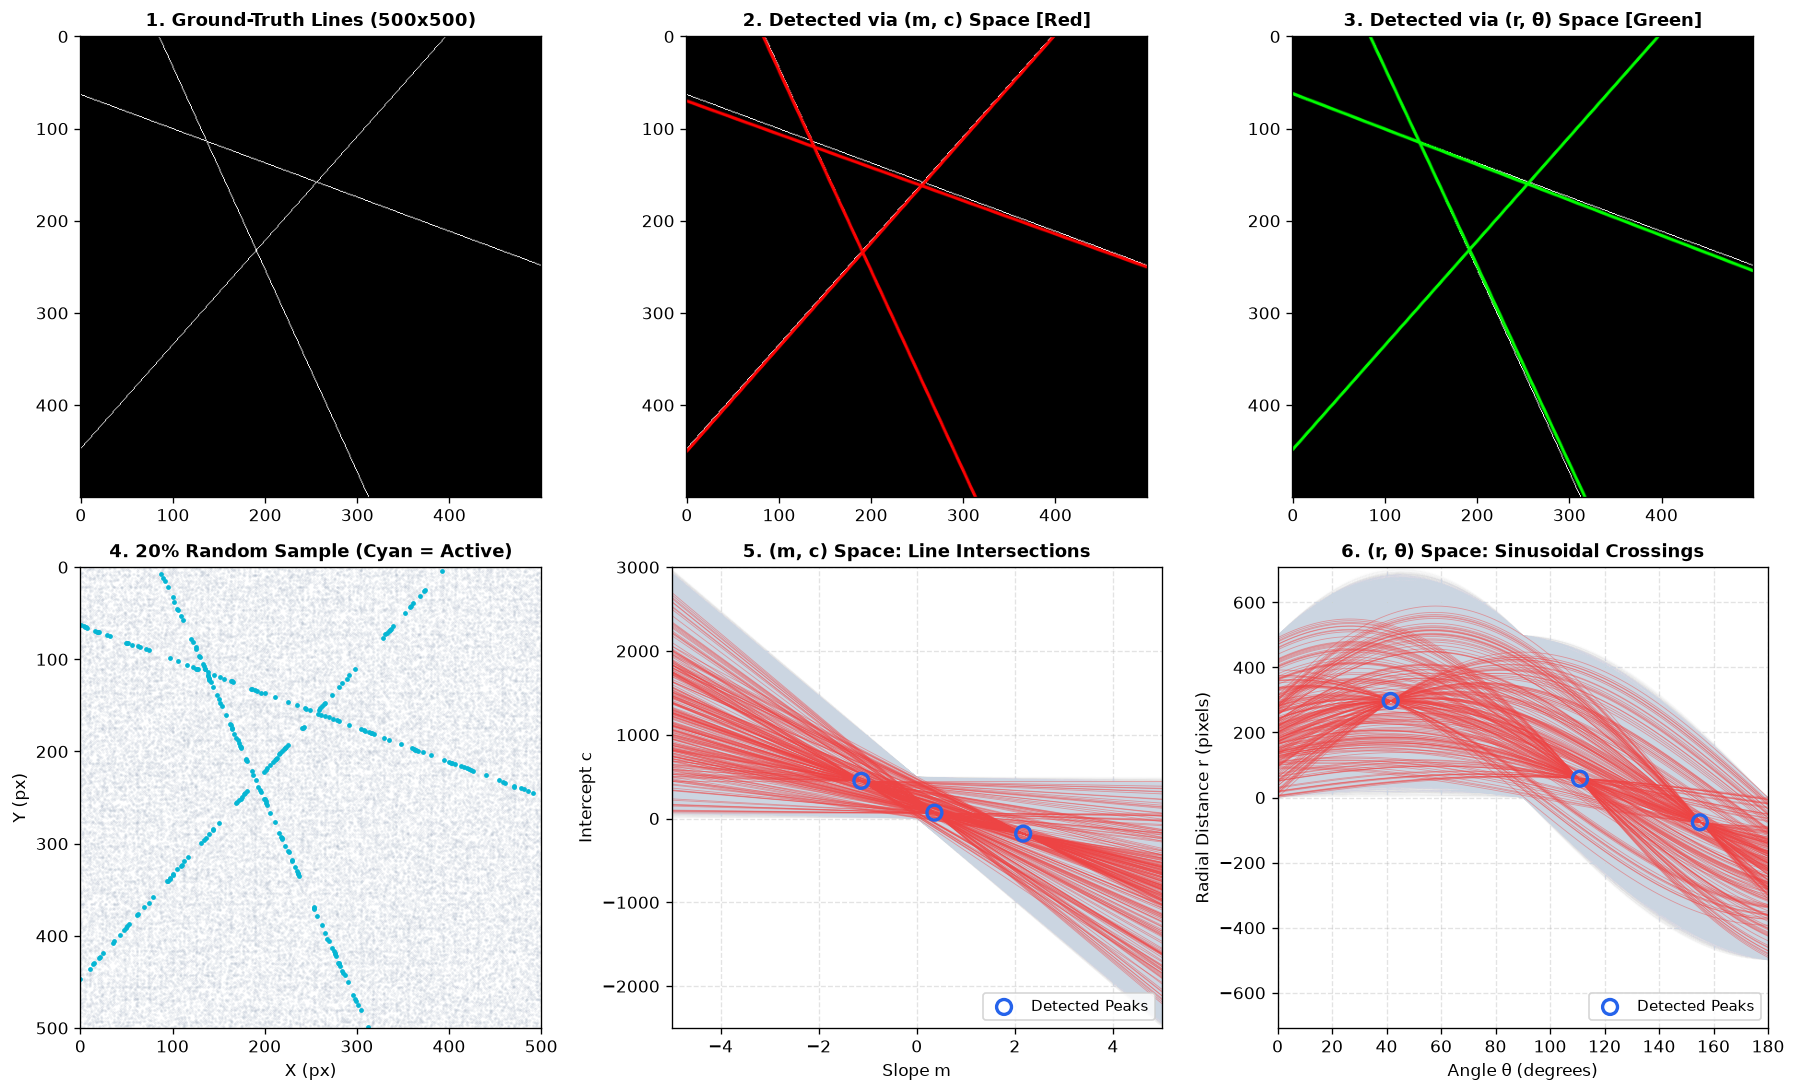

In [7]:
# Compute parameter space curves for visualization
t_plot_deg = np.linspace(0, 180, 91)
t_plot = np.deg2rad(t_plot_deg)

def curves_mc(px, py):
    # Straight lines: c = y - m * x evaluated at m = -5 and m = 5
    return np.stack([np.stack([np.full(len(px), -5.0), py + 5 * px], axis=1),
                     np.stack([np.full(len(px), 5.0), py - 5 * px], axis=1)], axis=1)

def curves_rt(px, py):
    # Sinusoids: r = x * cos(t) + y * sin(t)
    r = px[:, None] * np.cos(t_plot) + py[:, None] * np.sin(t_plot)
    return np.stack([np.broadcast_to(t_plot_deg, r.shape), r], axis=-1)

# Comprehensive 2x3 Dashboard with fixed sizing and proper aspect ratios
fig, ax = plt.subplots(2, 3, figsize=(15, 9.2), dpi=120)

# Row 0: Image-space plots (strictly square aspect)
ax[0, 0].imshow(img, cmap="gray")
ax[0, 0].set_title("1. Ground-Truth Lines (500x500)", fontsize=11, fontweight="bold")
ax[0, 0].set_aspect("equal")

ax[0, 1].imshow(out_mc[..., ::-1])
ax[0, 1].set_title("2. Detected via (m, c) Space [Red]", fontsize=11, fontweight="bold")
ax[0, 1].set_aspect("equal")

ax[0, 2].imshow(out_rt[..., ::-1])
ax[0, 2].set_title("3. Detected via (r, θ) Space [Green]", fontsize=11, fontweight="bold")
ax[0, 2].set_aspect("equal")

# Row 1: Sampling and Parameter Space Duals (fixed aspect, no stretching)
ax[1, 0].scatter(x[~on], y[~on], s=0.2, color="#94a3b8", alpha=0.15)
ax[1, 0].scatter(x[on], y[on], s=3.5, color="#06b6d4")
ax[1, 0].set_xlim(0, W)
ax[1, 0].set_ylim(H, 0)
ax[1, 0].set_aspect("equal")  # Enforce square aspect ratio!
ax[1, 0].set_title("4. 20% Random Sample (Cyan = Active)", fontsize=11, fontweight="bold")
ax[1, 0].set_xlabel("X (px)")
ax[1, 0].set_ylabel("Y (px)")

# (m, c) space: concurrent lines
ax[1, 1].add_collection(LineCollection(curves_mc(x[~on], y[~on]), colors="#cbd5e1", linewidths=0.2, alpha=0.03))
ax[1, 1].add_collection(LineCollection(curves_mc(x[on], y[on]), colors="#ef4444", linewidths=0.5, alpha=0.45))
ax[1, 1].scatter(*zip(*est_mc), s=80, facecolors="none", edgecolors="#2563eb", linewidths=2.0, zorder=5, label="Detected Peaks")
ax[1, 1].set_xlim(-5, 5)
ax[1, 1].set_ylim(c_min, c_max)
ax[1, 1].set_title("5. (m, c) Space: Line Intersections", fontsize=11, fontweight="bold")
ax[1, 1].set_xlabel("Slope m")
ax[1, 1].set_ylabel("Intercept c")
ax[1, 1].legend(loc="lower right", fontsize=9)
ax[1, 1].grid(True, linestyle="--", alpha=0.35)

# (r, theta) space: sinusoidal crossings
ax[1, 2].add_collection(LineCollection(curves_rt(x[~on], y[~on]), colors="#cbd5e1", linewidths=0.2, alpha=0.03))
ax[1, 2].add_collection(LineCollection(curves_rt(x[on], y[on]), colors="#ef4444", linewidths=0.5, alpha=0.45))
ax[1, 2].scatter([np.rad2deg(thetas[i]) for i, _, _ in peaks_rt], [r_vals[j] for _, j, _ in peaks_rt],
                 s=80, facecolors="none", edgecolors="#2563eb", linewidths=2.0, zorder=5, label="Detected Peaks")
ax[1, 2].set_xlim(0, 180)
ax[1, 2].set_ylim(-diag, diag)
ax[1, 2].set_title("6. (r, θ) Space: Sinusoidal Crossings", fontsize=11, fontweight="bold")
ax[1, 2].set_xlabel("Angle θ (degrees)")
ax[1, 2].set_ylabel("Radial Distance r (pixels)")
ax[1, 2].legend(loc="lower right", fontsize=9)
ax[1, 2].grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.savefig("hough_comprehensive_dashboard.png", dpi=200)
plt.show()


### Step 7: Observations & Conclusions
1. **Duality Properties:**
   - In Cartesian $(m, c)$ space, collinear image points map to lines that concur at $(m^*, c^*)$.
   - In Polar $(r, \theta)$ space, collinear image points map to sinusoidal trajectories that intersect at $(r^*, \theta^*)$.
2. **Singularity & Boundedness:**
   - Cartesian $(m, c)$ space suffers from unbounded growth as lines approach vertical orientation ($m \to \pm\infty$, $c \to \pm\infty$).
   - Polar $(r, \theta)$ parameterization completely avoids singularities because $\theta \in [0, \pi)$ is periodic and bounded, while $r \in [-\text{diag}, \text{diag}]$ is strictly confined by image dimensions.
3. **Parameter Accuracy:**
   - Polar Hough transformation exhibits significantly superior intercept accuracy (error $\le 1.2$ px for in-bounds lines vs. up to $10.0$ px in $(m, c)$ space).
4. **Peeling Effectiveness:**
   - The iterative weight peeling method successfully extracted all 3 lines without requiring prior knowledge of the total line count, avoiding duplicate cluster detections near dominant peaks.
